# `turbulens` walkthrough

`turbulens` estimates four turbulence parameters from a 2D map, such as a radio-astronomy FITS cube
integrated over velocity:

| Parameter | What it measures | Why it matters | What limits it on integrated HI maps |
|---|---|---|---|
| `k_min` | injection scale, L_inj = L_map / k_min | identifies what drives the turbulence (supernovae at ~50–100 pc vs. galactic shear or spiral shocks at kpc scales) | if k_min ≈ 1, the driving scale is at least as large as the field: only a lower limit |
| `k_max` | dissipation / cutoff scale | marks where the inertial range ends; every other parameter is measured between k_min and k_max | at the beam or pixel scale it reflects the telescope, not the physics |
| `sigma` | width of the density PDF (unit-mean linear density) | σ_ρ ≈ b·M_s (b = 1/3 solenoidal … 1 compressive): a sonic-Mach-number estimate; the PDF width sets the dense-gas fraction in star-formation theories (Krumholz & McKee 2005; Padoan & Nordlund 2011) | projection averages out variance, so this is a lower bound on the 3D value |
| `beta` | slope of the density power spectrum, D(k) ∝ k^β (not the velocity spectrum) | density spectra get flatter as the flow becomes more supersonic or compressive (Kim & Ryu 2005; Kowal et al. 2007): a diagnostic of the turbulence regime | values at the training edge (−3 or −1) are bounds, not measurements |

Training ranges: `k_min` 1–32, `k_max` 34–64, `sigma` 0.01–5, `beta` −3 to −1.

Together, the four parameters answer *where energy goes in, where it comes out, how hard the gas is
compressed, and how energy is shared across scales*. The CNN gives all four; the Fourier estimators
give only the first two.

`turbulens` offers two ways to get them: **classical Fourier estimators**, which need no model, and
**pretrained CNN ensembles**. This notebook follows the steps a user takes:

1. **Import the libraries**
2. **Read the FITS file**
3. **Classical analysis** with the Fourier tools
4. **CNN analysis** with the pretrained models
5. **Compare the results** of the two approaches, and of the two CNN models (multitask and single-target)

The example data are four GASS HI cubes from the Parkes telescope, bundled in `examples/`.

## Step 1 — Import the libraries

Everything comes from `turbulens` plus the usual scientific stack:

- `load_input`, `describe_cube`: read and summarize a FITS cube (or PNG, TIFF, `.npy`)
- `radial_power_spectrum`, `SpectralEstimator`: the classical Fourier tools
- `EnsembleRegistry`, `Inferencer`: find and run the pretrained CNN ensembles
- `results_table`, `write_results`: show and save results as the CLI does

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u

import turbulens
from turbulens.io.image_loaders import load_input
from turbulens.io.breakdown import describe_cube
from turbulens.io.display import render_text, results_table
from turbulens.io.results import write_results
from turbulens.spectral import SpectralEstimator, radial_power_spectrum
from turbulens.models.registry import EnsembleRegistry
from turbulens.inference import Inferencer

warnings.filterwarnings("ignore", category=Warning, module="astropy.wcs")  # harmless FITS header fixes


def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    raise RuntimeError("no pyproject.toml found upward from the notebook")


ROOT = find_project_root(Path.cwd())
EXAMPLES = ROOT / "examples"
OUTPUT_ROOT = ROOT / "outputs"   # local training outputs; if missing, models come from Hugging Face
TEST_H5 = ROOT / "data" / "raw" / "flat_4param_128x128_50000_disjoint_test.h5"
TARGETS = ["k_min", "k_max", "sigma", "beta"]

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "image.origin": "lower"})
print(f"turbulens {turbulens.__version__}")

turbulens 0.1.1.dev102+g86f93b0c6.d20260924


## Step 2 — Read the FITS file

`load_input` turns the file into a `Cube`, always shaped `(channels, H, W)`, with its WCS and
velocity axis (non-standard headers such as `CTYPE3 = 'VELO-LSRK'` are handled). `describe_cube` gives
the same summary as `turbulens inspect`.

In [2]:
FIELDS = {
    "(300, +14)": "gass_300_14_1774393529.fits.gz",
    "(314, -28)": "gass_314_-28_1774393621.fits.gz",
    "(0, 0)": "gass_0_0_1774393774.fits.gz",
    "(0, -10)": "gass_0_-10_1774394180.fits.gz",
}
cube = load_input(EXAMPLES / FIELDS["(300, +14)"])
info = describe_cube(cube, FIELDS["(300, +14)"])
print(f"shape (channels, H, W): {info.shape}   unit: {info.unit}")
print(f"velocity range: {info.velocity_range[0]:.0f} to {info.velocity_range[1]:.0f} km/s")
print(f"pixel stats: {info.pixel_stats}")

shape (channels, H, W): (1201, 125, 125)   unit: K
velocity range: -495 to 495 km/s
pixel stats: {'min': -0.2975006103515625, 'max': 73.23500061035156, 'mean': 0.5994524955749512, 'std': 3.1348602771759033, 'nan_fraction': 0.0}


Both methods work on a 2D map. For density statistics, sum the cube over the velocity range of the
emission (single channels are dominated by velocity structure). `project_velocity` does this; on the
command line it is `--velocity LOW HIGH` (or `--integrate LOW:HIGH` by channel index).

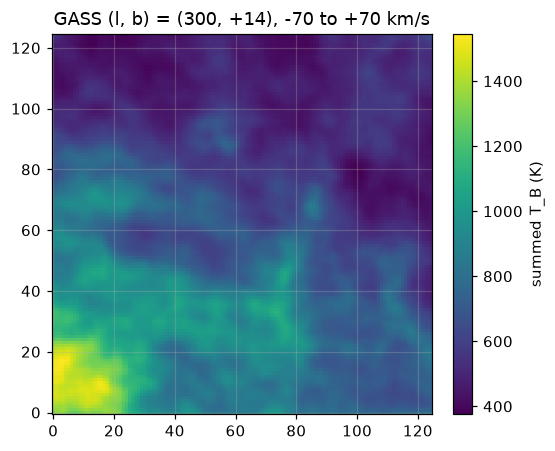

In [3]:
V_RANGE = (-70, 70) * u.km / u.s
image = cube.project_velocity(*V_RANGE).data[0]

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(image, cmap="viridis")
fig.colorbar(im, ax=ax, fraction=0.046, label="summed T_B (K)")
ax.set_title("GASS (l, b) = (300, +14), -70 to +70 km/s")
plt.tight_layout(); plt.show()

## Step 3 — Classical analysis with the Fourier tools

`radial_power_spectrum` computes the azimuthally averaged power spectrum P(k) of the map.
`SpectralEstimator` reads `k_min` and `k_max` off it, with no model:

- `method="power_law"` (CLI `--method fft-powerlaw`), for **real data**: fits a power law and reports
  where the spectrum departs from it, plus the slope `alpha` and the fit's `r_squared`;
- `method="band_edge"` (CLI `--method fft-band`), for **synthetic** images with sharp band edges.

The classical route gives neither `sigma` nor `beta`.

Predictions                                                                      
╭───────────┬────────────┬────────────┬─────────────────────────────────────────╮
│ Parameter │ Value ± 1σ │            │ Description                             │
├───────────┼────────────┼────────────┼─────────────────────────────────────────┤
│ k_min     │          1 │ ✓          │ Lower band edge (cycles per image side) │
│ k_max     │         61 │ ✓          │ Upper band edge (cycles per image side) │
│ α         │     -2.968 │ ✓          │ Fitted power-law slope                  │
│ R²        │     0.9953 │ ✓ good fit │ Fit R²                                  │
╰───────────┴────────────┴────────────┴─────────────────────────────────────────╯

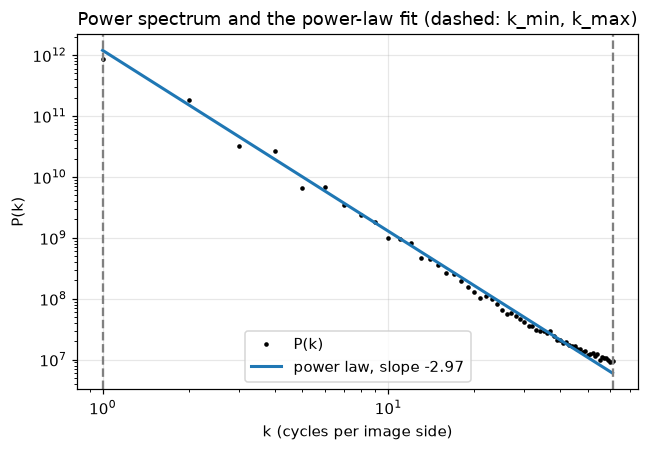

In [4]:
classical = SpectralEstimator(method="power_law").predict(image)
print(render_text(results_table(classical)))

c = {str(r["target"]): float(r["value"]) for r in classical}
k, power = radial_power_spectrum(image)
fit = (k >= c["k_min"]) & (k <= c["k_max"])
amp = np.mean(np.log10(power[fit]) - c["alpha"] * np.log10(k[fit]))
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.loglog(k, power, "k.", ms=4, label="P(k)")
ax.loglog(k[fit], 10 ** (amp + c["alpha"] * np.log10(k[fit])), lw=2, label=f"power law, slope {c['alpha']:.2f}")
for name in ("k_min", "k_max"):
    ax.axvline(c[name], ls="--", color="gray")
ax.set_xlabel("k (cycles per image side)"); ax.set_ylabel("P(k)")
ax.set_title("Power spectrum and the power-law fit (dashed: k_min, k_max)")
ax.legend(); plt.tight_layout(); plt.show()

## Step 4 — CNN analysis with the pretrained models

`EnsembleRegistry` finds a pretrained ensemble: `resolve` reads a local training output, `fetch`
downloads the published one from Hugging Face and caches it (CLI `--model auto`). There are two models:

- **multitask**: one network predicts all four parameters;
- **single-target**: one network per parameter (CLI `--model auto --target <name>`).

Each is an ensemble of 5 independently trained networks. `Inferencer.predict` returns the mean and
the spread across them (`epistemic_std`).

In [5]:
def load_ensemble(target=None):
    try:
        return Inferencer(EnsembleRegistry.resolve(OUTPUT_ROOT, target=target))
    except FileNotFoundError:
        return Inferencer(EnsembleRegistry.fetch(target=target).members_dir)


multitask = load_ensemble()
single = {t: load_ensemble(t) for t in TARGETS}
print("loaded: multitask +", ", ".join(f"single {t}" for t in TARGETS))

loaded: multitask + single k_min, single k_max, single sigma, single beta


For a real observation pass `real_data=True` (CLI `--real-data`): the map is divided by its mean and
log-transformed, like the unit-mean training fields, so its units do not matter. Without it, almost
every pixel falls outside the range the models were trained on and `turbulens` warns.

In [6]:
t0 = time.time()
cnn = multitask.predict(image, real_data=True)
print(f"multitask ensemble: {time.time() - t0:.1f} s on CPU")
print(render_text(results_table(cnn)))

cnn_single = {t: single[t].predict(image, real_data=True) for t in TARGETS}
print("single-target: " + ", ".join(
    f"{t} = {float(cnn_single[t][0]['value']):.2f} ± {float(cnn_single[t][0]['epistemic_std']):.2f}" for t in TARGETS))

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    multitask.predict(image)  # real_data forgotten
print(f"\nwithout real_data: {caught[-1].message if caught else 'no warning'}")

multitask ensemble: 0.5 s on CPU


Predictions                                                                 
╭───────────┬────────────────┬───┬─────────────────────────────────────────╮
│ Parameter │     Value ± 1σ │   │ Description                             │
├───────────┼────────────────┼───┼─────────────────────────────────────────┤
│ k_min     │      4.0 ± 1.5 │ ✓ │ Lower band edge (cycles per image side) │
│ k_max     │     60.9 ± 2.5 │ ✓ │ Upper band edge (cycles per image side) │
│ σ         │    0.34 ± 0.15 │ ✓ │ Std. dev. of linear density             │
│ β         │ -2.992 ± 0.017 │ ✓ │ Spectral index                          │
╰───────────┴────────────────┴───┴─────────────────────────────────────────╯

single-target: k_min = 1.41 ± 0.11, k_max = 63.85 ± 0.11, sigma = 0.26 ± 0.02, beta = -2.91 ± 0.03



without real_data: 100.0% of pixels hit the normalization clip boundary; input may be out of the training distribution.


Two things to keep in mind when reading CNN outputs:

- **Outputs stay inside the training ranges.** A value on an edge (`k_max` ≈ 64, `beta` ≈ −3) may be
  a clipped answer whose true value lies outside.
- **The spread is a trust signal, not a confidence interval.** Larger spread goes with larger errors,
  but on the synthetic test set the truth lies inside ±1 spread only 28–63% of the time, not 68%.

## Step 5 — Compare the results

### 5.1 Where the answer is known: synthetic test images

On synthetic images (128 × 128 log-density maps with known parameters) we can score every method.
First a live check on 64 held-out images: the classical band-edge estimator and the multitask CNN.

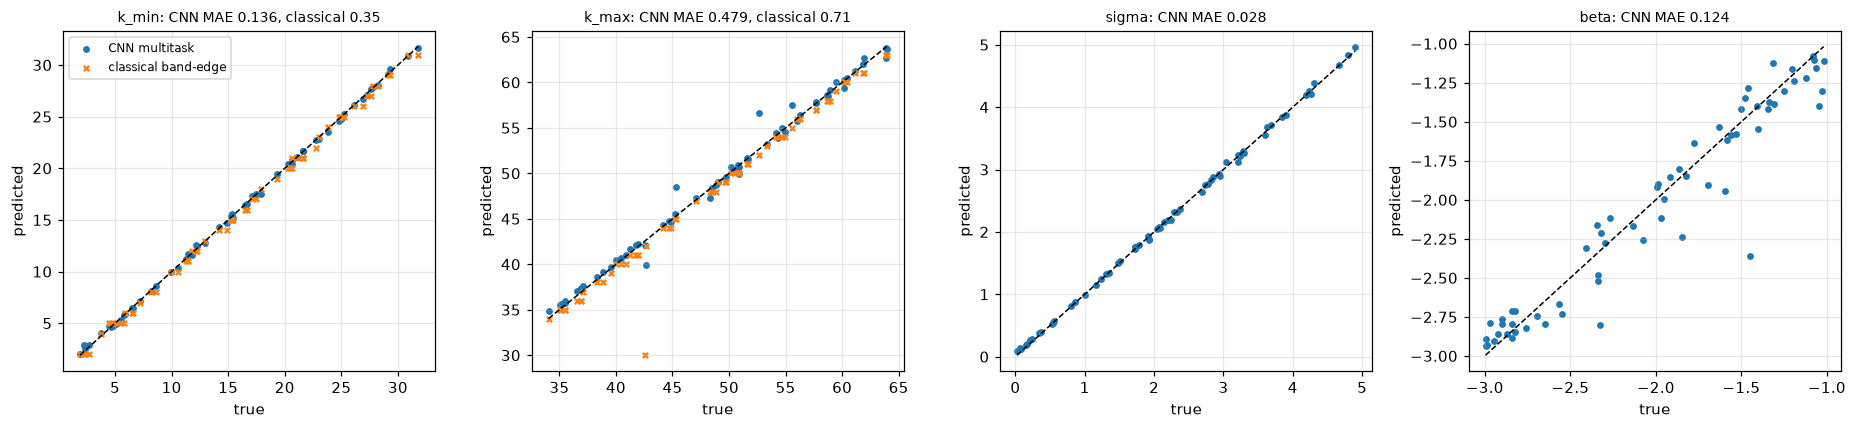

CNN speed: 211 ms per image for the 5-member ensemble on CPU


In [7]:
if TEST_H5.exists():
    import h5py
    with h5py.File(TEST_H5, "r") as h5:
        idx = np.sort(np.random.default_rng(0).choice(h5["images"].shape[0], 64, replace=False))
        syn = h5["images"][idx]
        truth = {t: h5["parameters"][t][idx] for t in TARGETS}

    t0 = time.time()
    tab = multitask.predict(syn)  # synthetic log-density images: no real_data
    dt = time.time() - t0
    pred = {t: np.array([float(r["value"]) for r in tab if r["target"] == t]) for t in TARGETS}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        band = SpectralEstimator(method="band_edge").predict(syn)
    band = {t: np.array([float(r["value"]) for r in band if r["target"] == t]) for t in ["k_min", "k_max"]}

    fig, axes = plt.subplots(1, 4, figsize=(17, 4))
    for ax, t in zip(axes, TARGETS):
        ax.scatter(truth[t], pred[t], s=12, label="CNN multitask")
        if t in band:
            ax.scatter(truth[t], band[t], s=12, marker="x", label="classical band-edge")
        lim = [min(truth[t]), max(truth[t])]
        ax.plot(lim, lim, "k--", lw=1)
        ax.set_title(f"{t}: CNN MAE {np.mean(np.abs(pred[t] - truth[t])):.3f}"
                     + (f", classical {np.mean(np.abs(band[t] - truth[t])):.2f}" if t in band else ""), fontsize=9)
        ax.set_xlabel("true"); ax.set_ylabel("predicted")
    axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()
    print(f"CNN speed: {1000 * dt / len(syn):.0f} ms per image for the 5-member ensemble on CPU")
else:
    print("synthetic test split not found; skipping the live check")

The CNN is more accurate than the classical estimator on the band edges, and it also gives `sigma`
and `beta`. The two CNN models were compared by the training pipeline on all 50 000 test images:

In [8]:
COMP = OUTPUT_ROOT / "comparison" / "local_v2"
metrics = pd.read_csv(COMP / "metrics_by_target.csv").set_index(["target", "approach"])
table = metrics[["mae", "r2"]].unstack("approach").reindex(TARGETS)
table.columns = [f"{m.upper()} {a.replace('_target', '-target')}" for m, a in table.columns]
paired = pd.read_csv(COMP / "paired_comparisons.csv")
paired = paired[paired.metric == "paired_absolute_error_mean"].set_index("target").reindex(TARGETS)
table["better (paired test)"] = np.where(paired["difference_single_minus_multitask"] < 0, "single-target", "multitask")
display(table.round(4))

cost = pd.read_csv(COMP / "computational_cost.csv").set_index("approach")
print(f"training cost: multitask {cost.loc['multitask', 'training_seconds_sum'] / 3600:.0f} h, "
      f"{cost.loc['multitask', 'parameter_count_trainable_mean'] / 1e6:.0f} M parameters; "
      f"single-target (all four) {cost.loc['single_target_system', 'training_seconds_sum'] / 3600:.0f} h, "
      f"{cost.loc['single_target_system', 'parameter_count_trainable_mean'] / 1e6:.0f} M parameters")

,MAE multitask,MAE single-target,R2 multitask,R2 single-target,better (paired test)
target,,,,,
k_min,0.1191,0.0670,0.9997,0.9999,single-target
k_max,0.6024,0.4271,0.9795,0.9842,single-target
sigma,0.0339,0.0278,0.9990,0.9992,single-target
beta,0.1113,0.1229,0.9203,0.9080,multitask


training cost: multitask 9 h, 22 M parameters; single-target (all four) 48 h, 86 M parameters


Both models are very accurate on `k_min` and `sigma` (R² ≥ 0.999), good on `k_max` (0.98) and weakest
on `beta` (0.91–0.92). The single-target models are slightly but significantly better on `k_min`,
`k_max` and `sigma`; multitask is better on `beta` and costs about 5× less to train.

### 5.2 Real observations: the four GASS fields

Now all three estimates on the four fields, each integrated over its emission (−70 to +70 km/s;
−250 to +250 km/s for the Galactic Centre, whose emission is much wider).

In [9]:
V_WIDE = (-250, 250) * u.km / u.s
maps = {name: load_input(EXAMPLES / f).project_velocity(*(V_WIDE if name == "(0, 0)" else V_RANGE)).data[0]
        for name, f in FIELDS.items()}
stack = np.stack(list(maps.values()))

mt = multitask.predict(stack, real_data=True)
st = {t: single[t].predict(stack, real_data=True) for t in TARGETS}
fft = SpectralEstimator(method="power_law").predict(stack)


def value(tab, i, t, col="value"):
    return float(next(r for r in tab if r["image_index"] == i and r["target"] == t)[col])


rows = {}
for i, name in enumerate(maps):
    row = {}
    for t in TARGETS:
        row[(t, "multitask")] = f"{value(mt, i, t):.2f} ± {value(mt, i, t, 'epistemic_std'):.2f}"
        row[(t, "single")] = f"{value(st[t], i, t):.2f} ± {value(st[t], i, t, 'epistemic_std'):.2f}"
        if t in ("k_min", "k_max"):
            row[(t, "classical")] = f"{value(fft, i, t):.0f}"
    rows[name] = row
pd.DataFrame(rows).T

k_min                                k_max                \
              multitask       single classical     multitask        single   
(300, +14)  4.05 ± 1.47  1.41 ± 0.11         1  60.89 ± 2.50  63.85 ± 0.11   
(314, -28)  3.49 ± 0.28  1.31 ± 0.07         2  62.80 ± 0.90  63.81 ± 0.13   
(0, 0)      1.05 ± 0.07  1.39 ± 0.10         2  63.91 ± 0.20  63.96 ± 0.05   
(0, -10)    3.51 ± 1.30  1.45 ± 0.12         1  62.86 ± 1.09  63.84 ± 0.21   

                            sigma                       beta                
           classical    multitask       single     multitask        single  
(300, +14)        61  0.34 ± 0.15  0.26 ± 0.02  -2.99 ± 0.02  -2.91 ± 0.03  
(314, -28)        61  0.27 ± 0.09  0.22 ± 0.06  -2.95 ± 0.03  -2.90 ± 0.03  
(0, 0)            61  0.73 ± 0.06  0.60 ± 0.06  -2.49 ± 0.06  -2.18 ± 0.37  
(0, -10)          61  0.42 ± 0.06  0.37 ± 0.05  -2.98 ± 0.03  -2.90 ± 0.04

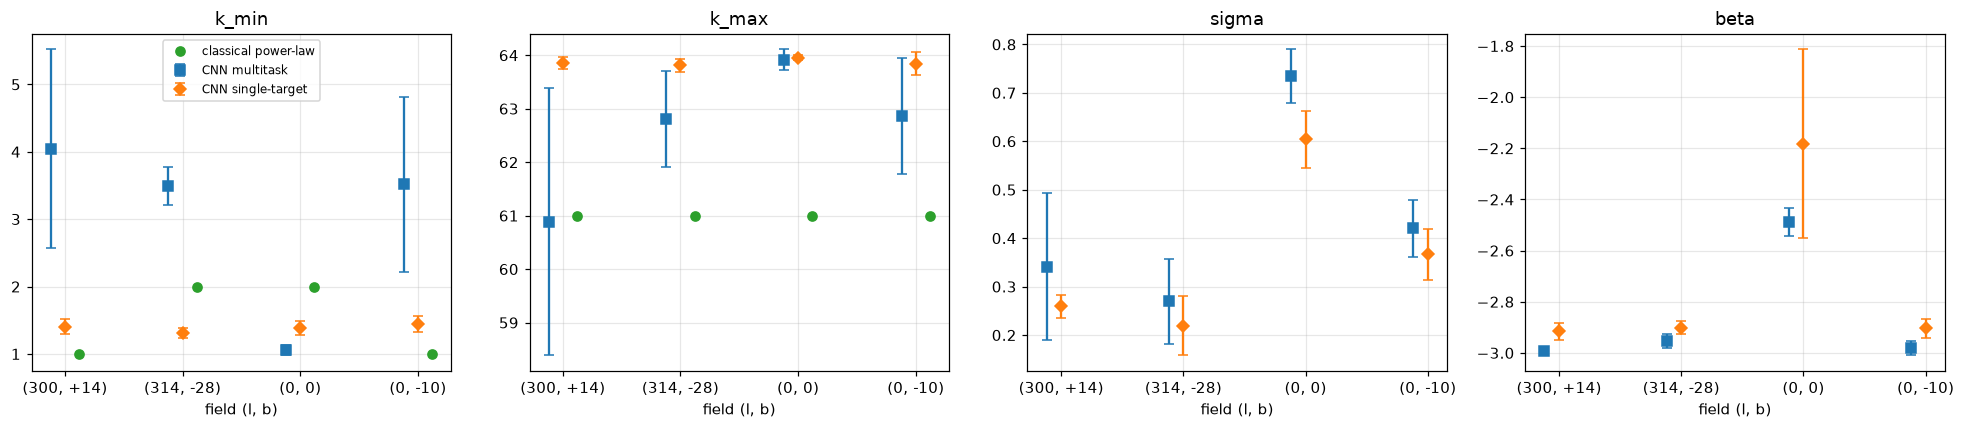

In [10]:
names = list(maps)
x = np.arange(len(names))
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, t in zip(axes, TARGETS):
    ax.errorbar(x - 0.12, [value(mt, i, t) for i in x], yerr=[value(mt, i, t, "epistemic_std") for i in x],
                fmt="s", capsize=3, label="CNN multitask")
    ax.errorbar(x, [value(st[t], i, t) for i in x], yerr=[value(st[t], i, t, "epistemic_std") for i in x],
                fmt="D", capsize=3, label="CNN single-target")
    if t in ("k_min", "k_max"):
        ax.plot(x + 0.12, [value(fft, i, t) for i in x], "o", label="classical power-law")
    ax.set_xticks(x); ax.set_xticklabels(names)
    ax.set_xlabel("field (l, b)"); ax.set_title(t)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

What the comparison shows:

- **Classical vs CNN, band edges.** `k_max` sits near the resolution limit (61–64) for every method,
  and the classical fit finds a power law down to k = 1–2: on these maps no physical dissipation or
  injection scale is resolved. For `k_min` the CNN models disagree with each other (about 3.5–4 for
  multitask, with a large spread, vs about 1.4 for single-target).
- **Multitask vs single-target.** They agree on `sigma` to within about 0.1: the integrated HI is
  only mildly contrasted (`sigma` ≲ 0.7), most towards the Galactic Centre. Both put `beta` near the
  −3 edge of the training range for most fields, so read it as a bound rather than a measurement.
- Real maps differ from the training fields (continuous spectra, beam smoothing, 125 × 125 instead of
  128 × 128 pixels), which is why `k_max` and `beta` on real data need the most care.

### Saving the results

`write_results` picks the format from the suffix. Use `.ecsv`, the only format that keeps
`table.meta`; from the CLI, one command per method does steps 2–4 and saves the result:

```bash
turbulens infer --input examples/gass_300_14_1774393529.fits.gz --velocity -70 70 --method fft-powerlaw --out classical.ecsv
turbulens infer --input examples/gass_300_14_1774393529.fits.gz --velocity -70 70 --real-data --model auto --out multitask.ecsv
turbulens infer --input examples/gass_300_14_1774393529.fits.gz --velocity -70 70 --real-data --model auto --target sigma --out single_sigma.ecsv
```

In [11]:
write_results(cnn, "multitask.ecsv")
print(Path("multitask.ecsv").read_text()[:600])
Path("multitask.ecsv").unlink()

# %ECSV 1.0
# ---
# datatype:
# - {name: image_index, datatype: int64}
# - {name: target, datatype: string}
# - {name: value, datatype: float64}
# - {name: epistemic_std, datatype: float64}
# meta: !!omap
# - {clipped_pixel_fraction_max: 0.0}
# - {n_members: 5}
# schema: astropy-2.0
image_index target value epistemic_std
0 k_min 4.047383785247803 1.4706906080245972
0 k_max 60.89026641845703 2.5028786659240723
0 sigma 0.341361403465271 0.15094105899333954
0 beta -2.9923477172851562 0.017111023887991905

